<a href="https://colab.research.google.com/github/kinjaljoshi/mech-interp-from-scratch/blob/master/1_3_covariance_and_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1.3 · The covariance matrix, and PCA as its eigendecomposition

*Phase 1 — linear algebra for interpretability*

Notebooks 1.1 and 1.2 were about a matrix acting on vectors. Here the matrix comes from data. Take a cloud of points, one per sample, and ask which directions it varies along the most. The answer turns out to be an eigenvector problem, and it uses exactly the machinery from 1.2: the covariance matrix is symmetric, so its eigenvalues are real, its eigenvectors are perpendicular, and $C = Q\Lambda Q^\top$.

That eigendecomposition *is* principal component analysis (PCA). It is also our first example of a basis chosen by the data instead of by us, and of an eigenvalue spectrum telling us how many directions matter. Both ideas return in every later phase.

As before, each step is a short note followed by one experiment cell. All numerics are PyTorch; matplotlib only draws.

1. Data as a cloud of points
2. Centering
3. The covariance matrix
4. Variance along any direction
5. PCA: the eigenvectors of $C$ are the principal axes
6. Scores: the data in its own axes
7. The variance budget
8. Dropping components: reconstruction and its exact error
9. A bigger example: the scree plot
10. PCA depends on the units
11. A preview: what PCA cannot see

## Setup

Same conventions as before, plus one for data. **Data matrices have one row per sample and one column per variable**, so $X$ has shape $(N, d)$. PyTorch's `torch.cov` expects the opposite (variables in rows), so we'll always call it on `X.T`.

Colours: blue is the data, orange and purple are the first and second principal axes, grey is for reference, and black marks ground truth we know in advance. `eig_sym` is the wrapper from 1.2, largest eigenvalue first.

In [1]:
import math
import torch
import matplotlib.pyplot as plt

torch.manual_seed(0)
torch.set_default_dtype(torch.float64)
torch.set_printoptions(precision=4, sci_mode=False, linewidth=120)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})

C_IN, C_OUT = "#6b7280", "#2563eb"          # reference (grey), data (blue)
C_V1, C_V2 = "#d97706", "#9333ea"           # first and second principal axis (orange, purple)

theta = torch.linspace(0, 2 * math.pi, 400)
circle = torch.stack([theta.cos(), theta.sin()])


def eig_sym(S):
    """Eigen-decomposition of a symmetric matrix, largest eigenvalue first. Columns of Q are orthonormal eigenvectors."""
    lam, Q = torch.linalg.eigh(S)                        # ascending order
    order = lam.argsort(descending=True)
    return lam[order], Q[:, order]


def arrow(ax, origin, vec, label, color, offset=(8, 6), ha="left", lw=2.4):
    """Arrow from origin along vec, with a label next to the tip."""
    tip = (origin + vec).tolist()
    ax.annotate("", xy=tip, xytext=origin.tolist(),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=lw), zorder=6)
    ax.annotate(label, xy=tip, xytext=offset, textcoords="offset points", ha=ha, fontsize=10, weight="bold",
                zorder=7, bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))


print("torch", torch.__version__)

torch 2.11.0+cpu


## Step 1 · Data as a cloud of points

We'll generate data whose true covariance we choose in advance, so that we can check what we recover. The matrix is the $S$ from notebook 1.2, which we already know has eigenvalues 6 and 1 with eigenvectors along 26.6° and 116.6°:

$$\Sigma = \begin{pmatrix} 5 & 2 \\ 2 & 2 \end{pmatrix}, \qquad \text{mean } \mu = (2, 1)$$

To draw samples with covariance $\Sigma$, take standard normal noise $z$ and apply a matrix $L$ with $LL^\top = \Sigma$ (the Cholesky factor): then $\operatorname{Cov}(Lz) = L\,I\,L^\top = \Sigma$. Each row of $X$ is one sample. Note how a matrix acting on a vector, as in 1.1, is what turns a round cloud into a tilted one.

X has shape (1000, 2)   (samples × variables)
first five samples:
 tensor([[-3.1662, -1.4754],
        [-0.3721,  1.1461],
        [ 0.0233, -1.1880],
        [ 0.6064, -0.5066],
        [-0.8971,  1.5102]])


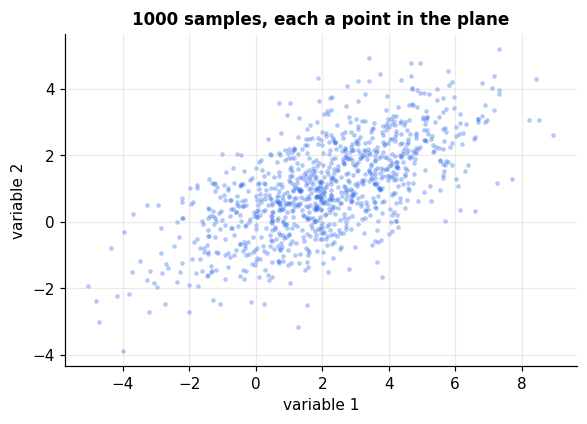

In [2]:
N = 1000
mu_true = torch.tensor([2.0, 1.0])
Sigma = torch.tensor([[5.0, 2.0],
                      [2.0, 2.0]])                  # the S from notebook 1.2

L = torch.linalg.cholesky(Sigma)                    # Σ = L Lᵀ
X = torch.randn(N, 2) @ L.T + mu_true               # one row per sample

print("X has shape", tuple(X.shape), "  (samples × variables)")
print("first five samples:\n", X[:5])

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(X[:, 0], X[:, 1], s=9, color=C_OUT, alpha=0.35, linewidths=0)
ax.set_aspect("equal"); ax.set_xlabel("variable 1"); ax.set_ylabel("variable 2")
ax.set_title(f"{N} samples, each a point in the plane")
plt.show()

## Step 2 · Centering

Covariance measures how variables move together *around their means*, so the first move is always to subtract the mean of each column. After centering, the cloud sits on the origin, and from here on the geometry of the data matches the geometry of linear maps from 1.1 and 1.2.

mean of each variable        : tensor([2.0756, 1.0154])
mean after centering         : tensor([-0.0000,  0.0000])


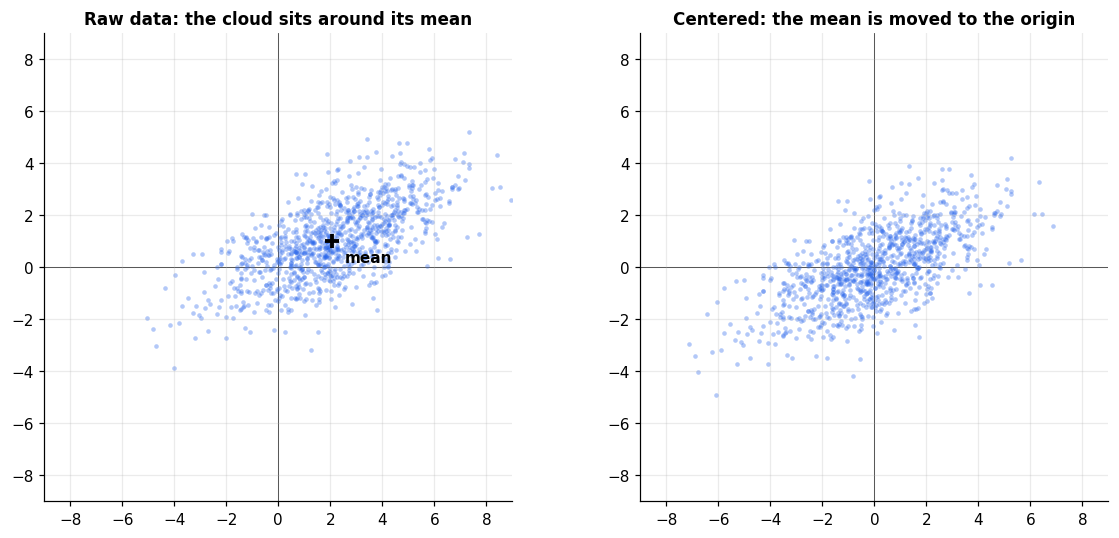

In [3]:
mean = X.mean(dim=0)                                # one mean per column
Xc = X - mean                                       # centered data

print("mean of each variable        :", mean)
print("mean after centering         :", Xc.mean(dim=0))
assert torch.allclose(Xc.mean(dim=0), torch.zeros(2), atol=1e-12)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, P, title in [(axes[0], X, "Raw data: the cloud sits around its mean"),
                     (axes[1], Xc, "Centered: the mean is moved to the origin")]:
    ax.scatter(P[:, 0], P[:, 1], s=9, color=C_OUT, alpha=0.35, linewidths=0)
    ax.axhline(0, color="k", lw=0.5, zorder=0); ax.axvline(0, color="k", lw=0.5, zorder=0)
    ax.set_xlim(-9, 9); ax.set_ylim(-9, 9); ax.set_aspect("equal"); ax.set_title(title)
axes[0].scatter(*mean.tolist(), s=90, color="black", marker="+", linewidths=2.5, zorder=5)
axes[0].annotate("mean", xy=mean.tolist(), xytext=(8, -14), textcoords="offset points", fontsize=10, weight="bold")
plt.tight_layout(); plt.show()

## Step 3 · The covariance matrix

For centered data the **sample covariance matrix** is

$$C = \frac{1}{N-1}\, X_c^\top X_c \qquad\text{so that}\qquad C_{jk} = \frac{1}{N-1}\sum_{n} x_{nj}\,x_{nk}$$

The diagonal entries are the variance of each variable. The off-diagonal entries are covariances: positive when two variables tend to rise together, negative when one rises as the other falls, zero when they are unrelated. (We divide by $N-1$ rather than $N$ because the mean was estimated from the same data; this is `torch.cov`'s default.)

We build $C$ by hand and then check it against PyTorch and against the $\Sigma$ the data was drawn from. The two will differ a little, because 1000 samples are only an estimate.

In [4]:
C = Xc.T @ Xc / (N - 1)                             # (2, 2): sum over samples of outer products, scaled
print("C =\n", C)
print("\ntrue Σ =\n", Sigma)

assert torch.allclose(C, torch.cov(X.T))            # torch.cov wants variables in rows, hence X.T
assert torch.allclose(C, Sigma, atol=0.8)           # an estimate, so close but not equal

var_1, var_2 = Xc[:, 0].var(), Xc[:, 1].var()       # diagonal entries are the plain variances
cov_12 = (Xc[:, 0] * Xc[:, 1]).sum() / (N - 1)      # off-diagonal entry
corr = cov_12 / (var_1.sqrt() * var_2.sqrt())       # covariance rescaled to lie in [-1, 1]
print(f"\nvariances {var_1:.3f}, {var_2:.3f}   covariance {cov_12:.3f}   correlation {corr:.3f}")
assert torch.allclose(torch.stack([var_1, var_2]), torch.diagonal(C))
assert torch.allclose(cov_12, C[0, 1]) and torch.allclose(corr, torch.corrcoef(X.T)[0, 1])

C =
 tensor([[5.0218, 2.0591],
        [2.0591, 2.0102]])

true Σ =
 tensor([[5., 2.],
        [2., 2.]])

variances 5.022, 2.010   covariance 2.059   correlation 0.648


$C$ is built the same way as the Gram matrices from 1.2 (Step 7). With $B = X_c/\sqrt{N-1}$ we have $C = B^\top B$, so it is automatically **symmetric and positive semi-definite**: real eigenvalues, perpendicular eigenvectors, and no negative variances. Everything from the spectral theorem applies.

In [5]:
B = Xc / math.sqrt(N - 1)
print("C == BᵀB            :", torch.allclose(C, B.T @ B))
print("C is symmetric      :", torch.allclose(C, C.T))
print("eigenvalues of C    :", torch.linalg.eigvalsh(C).flip(0), "  (all ≥ 0)")

x = torch.randn(2, 5000)
print("xᵀCx ≥ 0 for 5000 random x:", bool(((x * (C @ x)).sum(0) >= 0).all()))

C == BᵀB            : True
C is symmetric      : True
eigenvalues of C    : tensor([6.0670, 0.9651])   (all ≥ 0)
xᵀCx ≥ 0 for 5000 random x: True


## Step 4 · Variance along any direction

Choose a unit vector $u$ and project every sample onto it: the number $x_n^\top u$ says how far along $u$ the sample sits. The variance of those numbers has a closed form:

$$\operatorname{Var}(X_c u) = \frac{1}{N-1}\lVert X_c u\rVert^2 = u^\top\!\left(\frac{X_c^\top X_c}{N-1}\right)\!u = u^\top C\, u$$

This is exactly the quadratic form $x^\top S x$ from 1.2, Step 6. We showed there that on unit vectors it is largest along the top eigenvector, where it equals $\lambda_1$. So **the direction of greatest variance is the top eigenvector of $C$**, and that is the whole idea of PCA. Let's verify it by projecting the data in every direction.

largest variance : 6.0669 at 27.0°    (λ₁ = 6.0670, top eigenvector at 26.9°)
smallest variance: 0.9651 at 117.0°   (λ₂ = 0.9651)

variance along the x-axis: 5.022    along the y-axis: 2.010    along PC1: 6.067


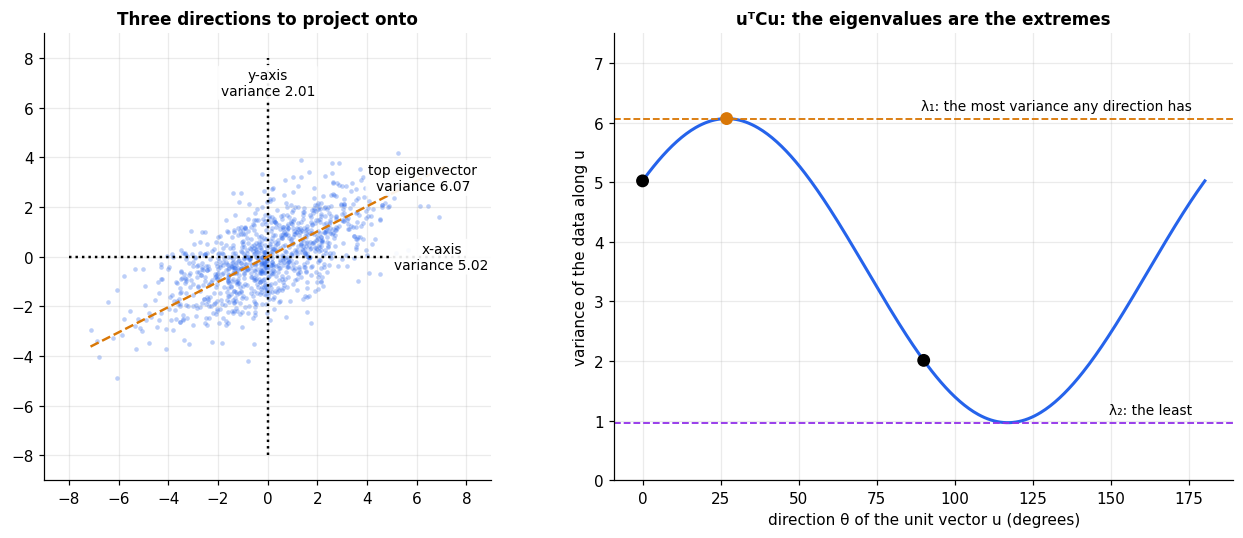

In [6]:
lam, Q = eig_sym(C)
th1 = math.atan2(Q[1, 0].item(), Q[0, 0].item()) % math.pi       # direction of the top eigenvector

thetas = torch.linspace(0, math.pi, 361)
U = torch.stack([thetas.cos(), thetas.sin()])                     # (2, 361): one unit direction per column

var_formula = (U * (C @ U)).sum(0)                                # uᵀCu for every direction
var_measured = (Xc @ U).var(dim=0)                                # actually project the data and take the variance
assert torch.allclose(var_formula, var_measured)

print(f"largest variance : {var_formula.max():.4f} at {math.degrees(thetas[var_formula.argmax()]):.1f}°    (λ₁ = {lam[0]:.4f}, top eigenvector at {math.degrees(th1):.1f}°)")
print(f"smallest variance: {var_formula.min():.4f} at {math.degrees(thetas[var_formula.argmin()]):.1f}°   (λ₂ = {lam[1]:.4f})")
assert abs(var_formula.max() - lam[0]) < 1e-3 and abs(var_formula.min() - lam[1]) < 1e-3
print(f"\nvariance along the x-axis: {C[0, 0]:.3f}    along the y-axis: {C[1, 1]:.3f}    along PC1: {lam[0]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ax = axes[0]
ax.scatter(Xc[:, 0], Xc[:, 1], s=9, color=C_OUT, alpha=0.3, linewidths=0)
for ang, color, ls, lab, val in [(0.0, "black", ":", "x-axis", C[0, 0]),
                                 (math.pi / 2, "black", ":", "y-axis", C[1, 1]),
                                 (th1, C_V1, "--", "top eigenvector", lam[0])]:
    d = torch.tensor([math.cos(ang), math.sin(ang)])
    ax.plot([-8 * d[0], 8 * d[0]], [-8 * d[1], 8 * d[1]], color=color, ls=ls, lw=1.6, zorder=3)
    ax.annotate(f"{lab}\nvariance {val:.2f}", xy=(7.0 * d[0], 7.0 * d[1]), ha="center", va="center", fontsize=9,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.9), zorder=7)
ax.set_xlim(-9, 9); ax.set_ylim(-9, 9); ax.set_aspect("equal"); ax.set_title("Three directions to project onto")

ax = axes[1]
ax.plot(torch.rad2deg(thetas), var_formula, color=C_OUT, lw=2)
ax.axhline(lam[0].item(), color=C_V1, ls="--", lw=1.2); ax.axhline(lam[1].item(), color=C_V2, ls="--", lw=1.2)
ax.scatter([0, 90, math.degrees(th1)], [C[0, 0].item(), C[1, 1].item(), lam[0].item()],
           color=["black", "black", C_V1], s=55, zorder=5)
ax.text(176, lam[0].item() + 0.15, "λ₁: the most variance any direction has", ha="right", fontsize=9)
ax.text(176, lam[1].item() + 0.15, "λ₂: the least", ha="right", fontsize=9)
ax.set_xlabel("direction θ of the unit vector u (degrees)"); ax.set_ylabel("variance of the data along u")
ax.set_ylim(0, 7.5); ax.set_title("uᵀCu: the eigenvalues are the extremes")
plt.tight_layout(); plt.show()

## Step 5 · PCA: the eigenvectors of $C$ are the principal axes

Now the full statement. Take the eigendecomposition $C = Q\Lambda Q^\top$ from the spectral theorem.

- The eigenvectors (columns of $Q$) are the **principal axes**, or principal components. They are perpendicular unit vectors.
- The eigenvalues $\lambda_i$ are the **variance of the data along each axis**, so $\sqrt{\lambda_i}$ is its standard deviation in that direction.

The cloud of a Gaussian is an ellipse, and the principal axes are the axes of that ellipse. The matrix square root $C^{1/2} = Q\Lambda^{1/2}Q^\top$ maps the unit circle to the 1σ ellipse, which makes a good check: for 2D Gaussian data, the fractions of points within 1σ and 2σ (in the Mahalanobis sense) should be $1 - e^{-1/2} \approx 39\%$ and $1 - e^{-2} \approx 86\%$.

PC1: direction [0.8917063470267858, 0.452614395122543]  (  26.9°)   variance λ = 6.067   std √λ = 2.463
PC2: direction [-0.452614395122543, 0.8917063470267858]  ( 116.9°)   variance λ = 0.965   std √λ = 0.982
within 1σ: 39.1% of samples   (Gaussian theory: 39.3%)
within 2σ: 85.7% of samples   (Gaussian theory: 86.5%)


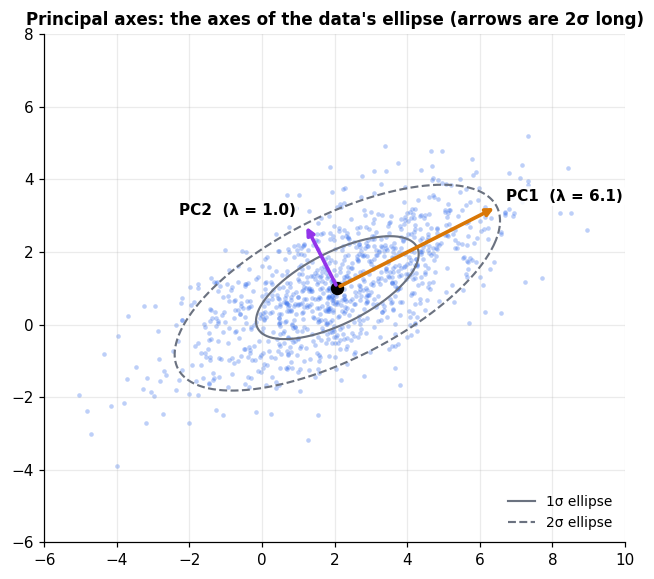

In [7]:
# signs are arbitrary; pick them so Q is a proper rotation (det = +1), as in 1.2
if Q[0, 0] < 0: Q[:, 0] = -Q[:, 0]
if torch.det(Q) < 0: Q[:, 1] = -Q[:, 1]

for i in range(2):
    ang = math.degrees(math.atan2(Q[1, i].item(), Q[0, i].item()))
    print(f"PC{i+1}: direction {Q[:, i].tolist()}  ({ang:6.1f}°)   variance λ = {lam[i]:.3f}   std √λ = {lam[i].sqrt():.3f}")

sqrtC = Q @ torch.diag(lam.sqrt()) @ Q.T            # matrix square root of C
assert torch.allclose(sqrtC @ sqrtC, C)

d2 = ((Xc @ torch.linalg.inv(C)) * Xc).sum(1)       # squared Mahalanobis distance of each sample
for k in (1, 2):
    frac, theory = (d2 <= k ** 2).double().mean().item(), 1 - math.exp(-k ** 2 / 2)
    print(f"within {k}σ: {frac:.1%} of samples   (Gaussian theory: {theory:.1%})")
    assert abs(frac - theory) < 0.04

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(X[:, 0], X[:, 1], s=9, color=C_OUT, alpha=0.3, linewidths=0)
for k, ls, lab in [(1, "-", "1σ ellipse"), (2, "--", "2σ ellipse")]:
    E = mean[:, None] + k * (sqrtC @ circle)
    ax.plot(E[0], E[1], color=C_IN, ls=ls, lw=1.4, label=lab)
arrow(ax, mean, 2 * lam[0].sqrt() * Q[:, 0], f"PC1  (λ = {lam[0]:.1f})", C_V1, offset=(6, 4))
arrow(ax, mean, 2 * lam[1].sqrt() * Q[:, 1], f"PC2  (λ = {lam[1]:.1f})", C_V2, offset=(-6, 6), ha="right")
ax.scatter(*mean.tolist(), s=60, color="black", zorder=5)
ax.set_xlim(-6, 10); ax.set_ylim(-6, 8); ax.set_aspect("equal")
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.set_title("Principal axes: the axes of the data's ellipse (arrows are 2σ long)")
plt.show()

## Step 6 · Scores: the data in its own axes

To express the data in principal-axis coordinates, project each centered sample onto the eigenvectors:

$$Z = X_c Q \qquad\text{(each row of } Z \text{ holds a sample's \textbf{scores})}$$

In these coordinates the covariance matrix is $\frac{1}{N-1}Z^\top Z = Q^\top C\, Q = \Lambda$. It is diagonal, so the new variables are **uncorrelated**, and the variance of each one is its eigenvalue. PCA is a rotation of the data into the one orthogonal frame in which the covariance has no cross terms.

covariance of the scores:
 tensor([[ 6.0670, -0.0000],
        [-0.0000,  0.9651]])

correlation between the original variables: +0.648
correlation between PC1 and PC2 scores     : -3.5e-17


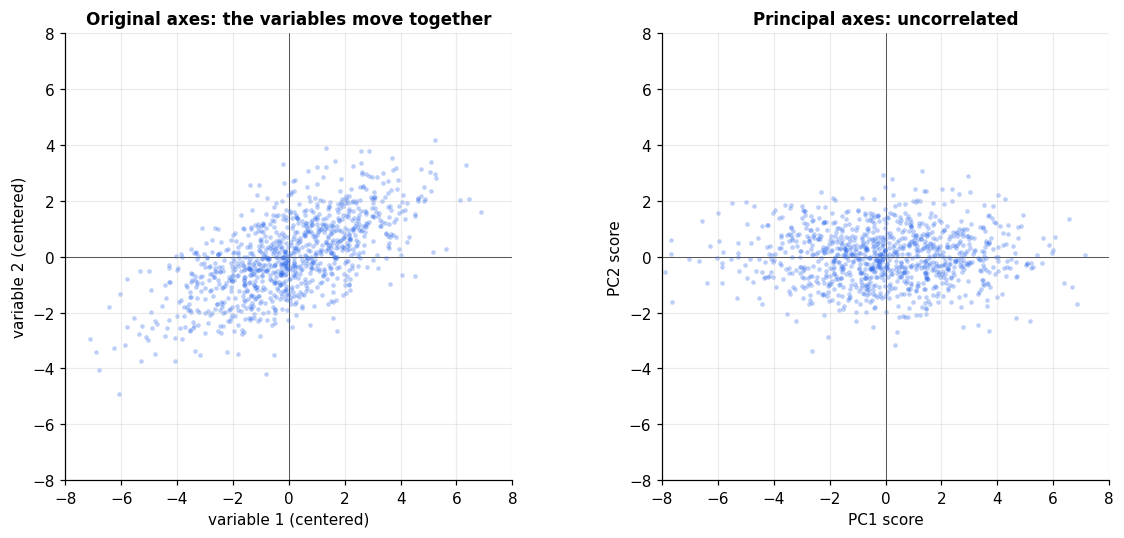

In [8]:
Z = Xc @ Q                                          # scores: the data in principal-axis coordinates
Cz = Z.T @ Z / (N - 1)
print("covariance of the scores:\n", Cz)
assert torch.allclose(Cz, torch.diag(lam), atol=1e-10)

print(f"\ncorrelation between the original variables: {torch.corrcoef(X.T)[0, 1]:+.3f}")
print(f"correlation between PC1 and PC2 scores     : {torch.corrcoef(Z.T)[0, 1]:+.1e}")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, P, title, xl, yl in [(axes[0], Xc, "Original axes: the variables move together", "variable 1 (centered)", "variable 2 (centered)"),
                             (axes[1], Z, "Principal axes: uncorrelated", "PC1 score", "PC2 score")]:
    ax.scatter(P[:, 0], P[:, 1], s=9, color=C_OUT, alpha=0.3, linewidths=0)
    ax.axhline(0, color="k", lw=0.5, zorder=0); ax.axvline(0, color="k", lw=0.5, zorder=0)
    ax.set_xlim(-8, 8); ax.set_ylim(-8, 8); ax.set_aspect("equal")
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(yl)
plt.tight_layout(); plt.show()

A preview of Phase 2. We never need to form $C$ at all: the SVD of the centered data matrix gives the same principal axes directly, with the singular values $s_i$ related to the eigenvalues by $\lambda_i = s_i^2/(N-1)$. Notebook 2 explains why; for now just confirm it.

In [9]:
U_, s, Vh = torch.linalg.svd(Xc, full_matrices=False)
print("eigenvalues of C      :", lam)
print("singular values² /(N−1):", s ** 2 / (N - 1))
assert torch.allclose(s ** 2 / (N - 1), lam)
assert torch.allclose(Vh.T.abs(), Q.abs())          # same axes (up to sign)
print("✓ SVD of the data gives the same principal axes and variances")

eigenvalues of C      : tensor([6.0670, 0.9651])
singular values² /(N−1): tensor([6.0670, 0.9651])
✓ SVD of the data gives the same principal axes and variances


## Step 7 · The variance budget

From 1.1 we know that the trace of a matrix equals the sum of its eigenvalues. For a covariance matrix the trace is the sum of the variances of the individual variables, so it has a name: the **total variance**. Rotating the axes cannot change it, but it changes how that total is *divided* among the axes. PCA arranges the split so that as much as possible goes to the first axis, then the second, and so on:

$$\text{explained variance ratio of PC}_i = \frac{\lambda_i}{\sum_j \lambda_j}$$

In [10]:
total = torch.trace(C)
print(f"trace(C)                          : {total:.4f}")
print(f"sum of the variances of x and y   : {Xc.var(0).sum():.4f}")
print(f"sum of the eigenvalues            : {lam.sum():.4f}")
assert torch.allclose(total, lam.sum()) and torch.allclose(total, Xc.var(0).sum())

evr = lam / lam.sum()
print(f"\nin the original axes: variable 1 holds {C[0, 0] / total:.1%} of the variance, variable 2 holds {C[1, 1] / total:.1%}")
print(f"in the principal axes: PC1 holds {evr[0]:.1%}, PC2 holds {evr[1]:.1%}")

trace(C)                          : 7.0320
sum of the variances of x and y   : 7.0320
sum of the eigenvalues            : 7.0320

in the original axes: variable 1 holds 71.4% of the variance, variable 2 holds 28.6%
in the principal axes: PC1 holds 86.3%, PC2 holds 13.7%


## Step 8 · Dropping components: reconstruction and its exact error

If PC2 carries little variance, we might keep only PC1. Each sample is then replaced by its projection onto the PC1 line, plus the mean back:

$$\hat{x} = \mu + (x_c^\top q_1)\, q_1$$

The mean squared error of doing this is not just small, it is exactly known: **the error equals the sum of the eigenvalues we threw away.** (This is Eckart–Young for the covariance matrix, and it returns in Phase 2.) Here only $\lambda_2$ is discarded.

reconstruction error with 1 component : 0.9651
the discarded eigenvalue λ₂           : 0.9651
residuals are perpendicular to PC1    : 2.3e-15


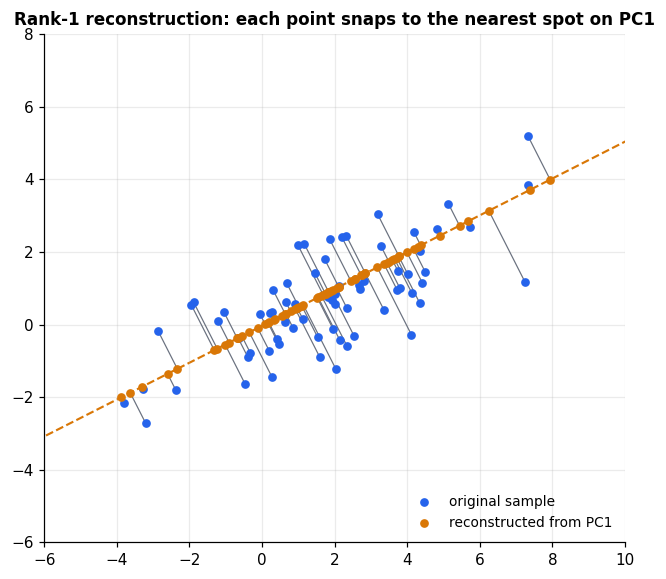

In [11]:
q1 = Q[:, :1]                                       # keep only the first principal axis, shape (2, 1)
X_hat = mean + (Xc @ q1) @ q1.T                     # project onto PC1, then add the mean back
resid = X - X_hat

mse = (resid ** 2).sum() / (N - 1)
print(f"reconstruction error with 1 component : {mse:.4f}")
print(f"the discarded eigenvalue λ₂           : {lam[1]:.4f}")
assert torch.allclose(mse, lam[1])

print(f"residuals are perpendicular to PC1    : {(resid @ q1).abs().max():.1e}")

idx = torch.randperm(N)[:70]
fig, ax = plt.subplots(figsize=(7, 6))
d = Q[:, 0]
ax.plot([mean[0] - 9 * d[0], mean[0] + 9 * d[0]], [mean[1] - 9 * d[1], mean[1] + 9 * d[1]], color=C_V1, ls="--", lw=1.4, zorder=1)
for n in idx.tolist():
    ax.plot([X[n, 0], X_hat[n, 0]], [X[n, 1], X_hat[n, 1]], color=C_IN, lw=0.8, zorder=2)
ax.scatter(X[idx, 0], X[idx, 1], s=22, color=C_OUT, zorder=3, label="original sample")
ax.scatter(X_hat[idx, 0], X_hat[idx, 1], s=22, color=C_V1, zorder=4, label="reconstructed from PC1")
ax.set_xlim(-6, 10); ax.set_ylim(-6, 8); ax.set_aspect("equal")
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.set_title("Rank-1 reconstruction: each point snaps to the nearest spot on PC1")
plt.show()

## Step 9 · A bigger example: the scree plot

In two dimensions there is little to throw away. The real use of PCA is in many dimensions where the data lies close to a lower-dimensional subspace. We'll build 8-dimensional data from **3 hidden factors** mixed through a random matrix $W$, plus a little independent noise of standard deviation 0.4 (variance 0.16) on every coordinate:

$$x = W f + \varepsilon, \qquad f \in \mathbb{R}^3$$

If PCA is doing its job, the covariance spectrum should show three large eigenvalues, one per factor, followed by a floor of five small ones near the noise variance. A bar plot of the eigenvalues is called a **scree plot**, and the bend where the bars flatten out is its elbow.

eigenvalues : tensor([60.6940, 42.8043,  6.6884,  0.1763,  0.1634,  0.1595,  0.1547,  0.1519])
noise variance used: 0.16    mean of the five smallest eigenvalues: 0.161
cumulative explained variance: tensor([0.5468, 0.9325, 0.9927, 0.9943, 0.9958, 0.9972, 0.9986, 1.0000])
✓ reconstruction error = sum of discarded eigenvalues, for every k


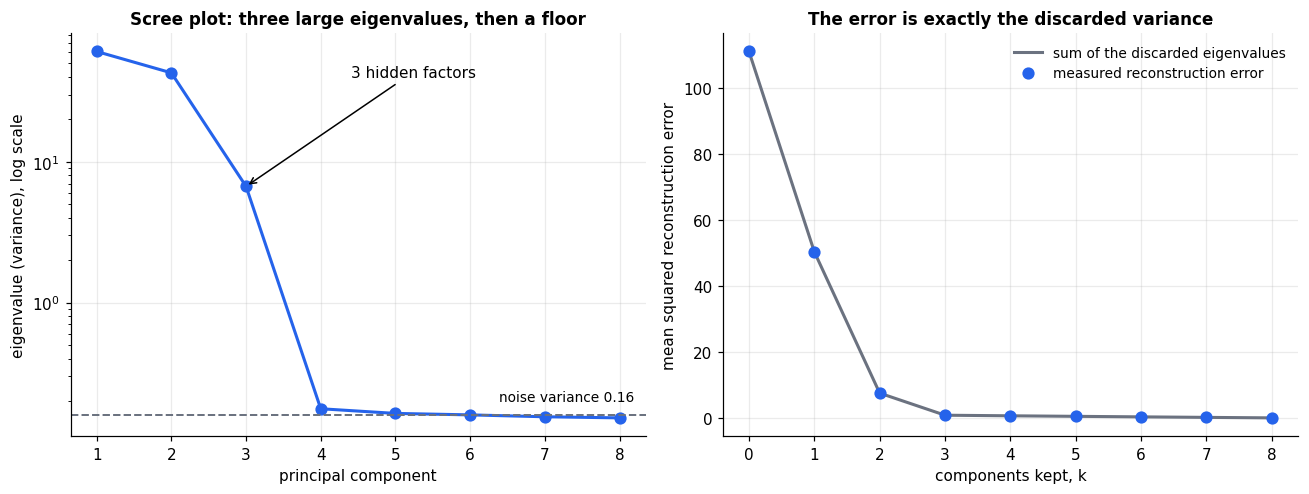

In [12]:
torch.manual_seed(1)
d, k_true, N2 = 8, 3, 2000
W = torch.randn(d, k_true)                                           # mixes 3 hidden factors into 8 observed variables
f = torch.randn(N2, k_true) * torch.tensor([3.0, 2.0, 1.2])          # factors with different strengths
X8 = f @ W.T + 0.4 * torch.randn(N2, d)                              # plus independent noise, variance 0.16

X8c = X8 - X8.mean(0)
C8 = X8c.T @ X8c / (N2 - 1)
lam8, Q8 = eig_sym(C8)
print("eigenvalues :", lam8)
print(f"noise variance used: {0.4 ** 2:.2f}    mean of the five smallest eigenvalues: {lam8[3:].mean():.3f}")
print("cumulative explained variance:", torch.cumsum(lam8, 0) / lam8.sum())

ks = list(range(d + 1))
measured, predicted = [], []
for k in ks:
    Qk = Q8[:, :k]                                                   # keep the top k principal axes
    resid = X8c - X8c @ Qk @ Qk.T
    measured.append((resid ** 2).sum().item() / (N2 - 1))
    predicted.append(lam8[k:].sum().item())                          # sum of the discarded eigenvalues
assert torch.allclose(torch.tensor(measured), torch.tensor(predicted))
print("✓ reconstruction error = sum of discarded eigenvalues, for every k")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ax = axes[0]
ax.semilogy(range(1, d + 1), lam8, "o-", color=C_OUT, lw=2, ms=7)
ax.axhline(0.16, color=C_IN, ls="--", lw=1.3)
ax.text(d + 0.2, 0.16 * 1.25, "noise variance 0.16", ha="right", fontsize=9)
ax.annotate("3 hidden factors", xy=(3, lam8[2]), xytext=(4.4, lam8[2] * 6), fontsize=10,
            arrowprops=dict(arrowstyle="->", color="black"), ha="left")
ax.set_xlabel("principal component"); ax.set_ylabel("eigenvalue (variance), log scale")
ax.set_title("Scree plot: three large eigenvalues, then a floor")

ax = axes[1]
ax.plot(ks, predicted, "-", color=C_IN, lw=2, label="sum of the discarded eigenvalues")
ax.plot(ks, measured, "o", color=C_OUT, ms=7, label="measured reconstruction error")
ax.set_xlabel("components kept, k"); ax.set_ylabel("mean squared reconstruction error")
ax.legend(frameon=False, fontsize=9); ax.set_title("The error is exactly the discarded variance")
plt.tight_layout(); plt.show()

## Step 10 · PCA depends on the units

The principal axes are defined by variance, and variance depends on the units each variable is measured in. Re-express the second variable in different units (metres to decimetres, say, a factor of 10) and its variance grows 100-fold, so it takes over the first principal component. Nothing about the underlying data has changed. The usual remedy is to **standardise** each variable first (divide by its standard deviation), which is the same as running PCA on the correlation matrix.

This is the first hint of a theme that grows: the answer PCA gives depends on a choice of basis and scale that the data does not itself fix.

In [13]:
def pc1_info(M):
    """Angle of PC1 (degrees from the first axis) and its share of the total variance."""
    Mc = M - M.mean(0)
    l, Qm = eig_sym(Mc.T @ Mc / (M.shape[0] - 1))
    return math.degrees(math.atan2(Qm[1, 0].item(), Qm[0, 0].item())) % 180, (l[0] / l.sum()).item()


variants = {
    "original units":                             X,
    "second variable ×10 (m → dm)":               X * torch.tensor([1.0, 10.0]),
    "standardised (each variable ÷ its std)":     (X - X.mean(0)) / X.std(0),
}
angles = {}
for name, M in variants.items():
    angles[name], share = pc1_info(M)
    print(f"{name:<42} PC1 at {angles[name]:5.1f}° from the first axis, explains {share:5.1%} of the variance")

a = list(angles.values())
assert abs(a[0] - 26.6) < 3 and a[1] > 80
assert abs(a[2] - 45) < 1e-6                         # for two standardised variables, PC1 is always the diagonal

original units                             PC1 at  26.9° from the first axis, explains 86.3% of the variance
second variable ×10 (m → dm)               PC1 at  84.1° from the first axis, explains 98.6% of the variance
standardised (each variable ÷ its std)     PC1 at  45.0° from the first axis, explains 82.4% of the variance


## Step 11 · A preview: what PCA cannot see

PCA finds orthogonal directions of maximum variance. What if the structure in the data is not made of orthogonal directions? Suppose the data is generated from two **features** pointing at $+30°$ and $-30°$ (60° apart, so not orthogonal), each active only 15% of the time, with a random strength when active:

$$x = s_1 d_1 + s_2 d_2, \qquad s_i = \text{(active with probability 0.15)} \times \mathcal{N}(0,1)$$

Most samples then lie along *one* of the two feature directions, which gives the cloud an X shape that the eye reads at once. The covariance, though, only records second moments: $C = 0.15\,(d_1 d_1^\top + d_2 d_2^\top)$. By symmetry that matrix has its eigenvectors along the bisector (0°) and its perpendicular (90°), with eigenvalues $0.15(1 \pm \cos 60°)$. PCA will therefore report axes that are *blends* of the true features.

Sparse, non-orthogonal features are the situation that superposition creates inside neural networks. We return to this in Phase 2 (what SVD can't tell you) and in earnest in Phase 4.

eigenvalues of C      : tensor([0.2297, 0.0760])    predicted: tensor([0.2250, 0.0750])
PC1 points at -0.5°;   the true features are at +30° and −30°

|cosine similarity|   rows: feature 1, feature 2    columns: PC1, PC2
 tensor([[0.8617, 0.5075],
        [0.8703, 0.4925]])

Every PC is a 30° blend of both features: neither feature is recovered.


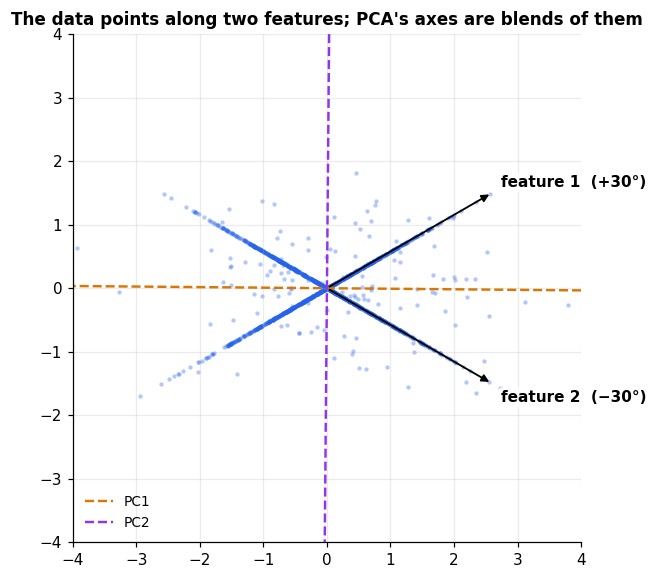

In [14]:
torch.manual_seed(2)
Np, p = 50000, 0.15
a = math.radians(30)
D = torch.tensor([[math.cos(a),  math.cos(a)],
                  [math.sin(a), -math.sin(a)]])             # columns: unit feature directions at +30° and −30°

sources = (torch.rand(Np, 2) < p).double() * torch.randn(Np, 2)   # sparse: each feature active ~15% of the time
Xs = sources @ D.T

Cs = Xs.T @ Xs / (Np - 1)                                    # the sources have mean zero, so no centering needed
lam_s, Q_s = eig_sym(Cs)
pc1_deg = math.degrees(math.atan2(Q_s[1, 0].item(), Q_s[0, 0].item())) % 180
if pc1_deg > 90: pc1_deg -= 180                              # an axis is a line, so report the angle in (−90°, 90°]
print("eigenvalues of C      :", lam_s, "   predicted:", torch.tensor([p * 1.5, p * 0.5]))
print(f"PC1 points at {pc1_deg:+.1f}°;   the true features are at +30° and −30°")
assert abs(pc1_deg) < 3

sim = (D.T @ Q_s).abs()                                      # |cosine| between each feature (rows) and each PC (columns)
print("\n|cosine similarity|   rows: feature 1, feature 2    columns: PC1, PC2\n", sim)
print("\nEvery PC is a 30° blend of both features: neither feature is recovered.")

idx = torch.randperm(Np)[:6000]
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(Xs[idx, 0], Xs[idx, 1], s=8, color=C_OUT, alpha=0.35, linewidths=0)
for i, (lab, off, ha) in enumerate([("feature 1  (+30°)", (6, 4), "left"), ("feature 2  (−30°)", (6, -12), "left")]):
    arrow(ax, torch.zeros(2), 3.0 * D[:, i], lab, "black", offset=off, ha=ha, lw=1.2)
for i, col in enumerate([C_V1, C_V2]):
    v = Q_s[:, i]
    ax.plot([-4 * v[0], 4 * v[0]], [-4 * v[1], 4 * v[1]], color=col, ls="--", lw=1.6, zorder=2, label=f"PC{i+1}")
ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal")
ax.legend(loc="lower left", frameon=False, fontsize=9)
ax.set_title("The data points along two features; PCA's axes are blends of them")
plt.show()

## Try it yourself

1. **Predict, then check.** For data with true covariance $\operatorname{diag}(4, 1)$, where should the principal axes point and what should the eigenvalues be? Generate the data with Step 1's recipe and verify.
2. **Skip the centering.** In Step 3, compute $X^\top X/(N-1)$ on the raw data and compare its eigenvectors with those of the centered covariance. What changes as you move the mean further from the origin?
3. **Rotate the cloud.** Multiply the data by a 45° rotation matrix and recompute PCA. How do the eigenvalues change, and how do the eigenvectors?
4. **Move the elbow.** In Step 9 raise the noise from 0.4 to 1.5, then to 3. At what noise level does the third factor stop being distinguishable from the floor?
5. **Reshape the X.** In Step 11 change the angle between the features from 60° to 90°, then to 20°. When does PCA recover the features, and when is it furthest off?

## What to carry forward

- The **covariance matrix** $C = X_c^\top X_c/(N-1)$ of centered data is symmetric and positive semi-definite, so the spectral theorem from 1.2 applies to it.
- The variance of the data along a unit direction $u$ is $u^\top C u$. Its maximum is $\lambda_1$, attained at the top eigenvector.
- **PCA is the eigendecomposition of $C$.** The eigenvectors are the principal axes, the eigenvalues are the variances along them, and the scores $Z = X_c Q$ are uncorrelated.
- The trace is the **total variance**. Keeping $k$ components leaves a reconstruction error equal to the sum of the discarded eigenvalues, so the **scree plot** tells you how many directions carry the signal.
- PCA is a statement about second moments, in a basis and scale it inherits from the data. It depends on the units, and it can only return orthogonal axes.
- For features that are sparse and not orthogonal, the principal axes are blends of them. This is the failure we will measure quantitatively in Phase 2 and Phase 4, and it motivates sparse autoencoders.

**Next, notebook 1.4:** degenerate eigenvalues, where the eigenvectors are not unique.